# AIList implementation and configuration benchmarking
This notebook shows benchmarking results for performance (execution time) for different implementations and configuration options for AIList. Its goal is to provide optimal default values for further benchmarking of the final solution.

### Local machine
Benchmarking was done on: Apple Studio M1 Ultra, 128GB RAM

In [43]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

## Implementation benchmark
Following graph shows execution time (y-axis) for different implementations of AIList with the same configuration options supplied. Each one is supplied with Scala iterator (as it is in Apache Spark library) and is expected to store the intervals in its own data structure. The tested implementations are:

### JavaAIListArray
This implementation is based on Java built-in ArrayList structure. ArrayList should offer better performance for in place operations, like sorting of the intervals that happens after loading the data from the iterator.
```java
public List<AIList> buildArrayFromIterator(final Iterator<Interval> scalaIterator) {
    ArrayList<Interval> intervalsList = new ArrayList<>();
    while(scalaIterator.hasNext())
        intervalsList.add(scalaIterator.next());

    intervalsList.sort(new IntervalComparator());
    return buildFromArray(intervalsList);
}
```

### JavaAIListQueue
This implementation uses PriorityQueue instead of the `.sort` method for sorting the intervals. Afterwards it still puts the intervals in the ArrayList - at later stages random access to the elements will be necessary.
```java
public List<AIList> buildQueueFromIterator(final Iterator<Interval> scalaIterator) {
    PriorityQueue<Interval> intervalsQueue = new PriorityQueue<>(new IntervalComparator());
    while(scalaIterator.hasNext())
        intervalsQueue.add(scalaIterator.next());

    ArrayList<Interval> intervals = new ArrayList<>(intervalsQueue.size());
    while(! intervalsQueue.isEmpty())
        intervals.add(intervalsQueue.poll());

    return buildFromArray(intervals);
}
```

### ScalaAIListArrayInPlace
This implementation is similar to JavaAIListArray, as it operates on Scala ArrayList structure and constructs components of the AIList by moving elements in the ArrayList. Since this algorithm does not need to move data from Scala data structure to its own one (both being Scala implementation), it is expected to yield better performance. It should also offer more stable memory usage due to not allocating additional structures.

### ScalaAIListDeque
This implementation uses ArrayList and Deque data structures instead of ArrayList to build components of the AIList. During construction of each AIList component, each interval is taken from the source ArrayList and appended either to ArrayList of current component or Deque for leftovers. This causes more memory usage, but yields simpler algorithm for building the AIList. 

### ScalaReference
This is reference implementation that does the most naive approach to construct the results, not using AIList. It exists to compare other implementations to. 
```scala
val result = for {
  lhsInterval <- database
  rhsInterval <- query
  if Interval.overlaps(lhsInterval, rhsInterval)
} yield (lhsInterval, rhsInterval)
```

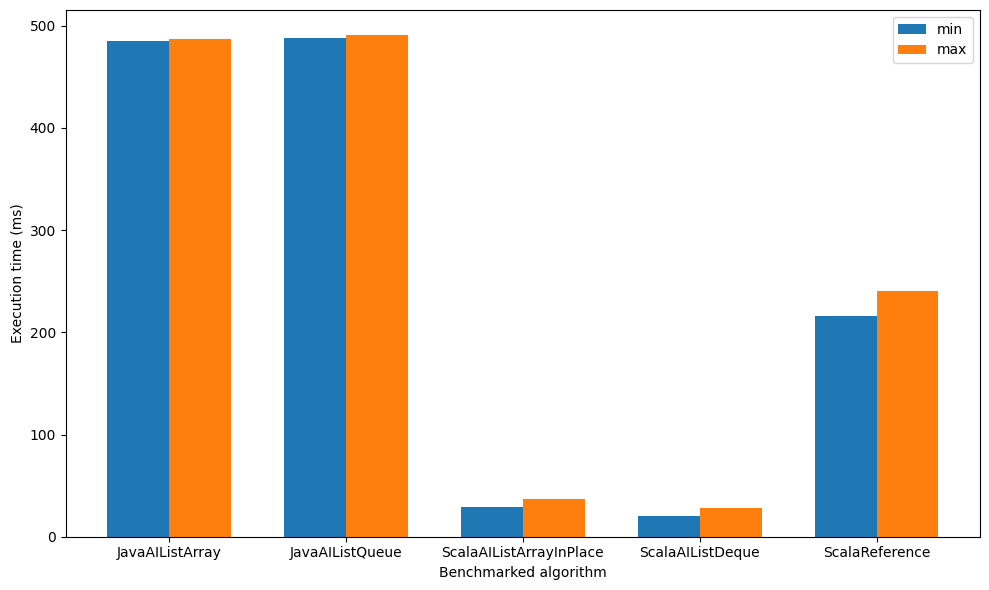

In [28]:
source_path = Path("..") / "results" / "ailist-benchmark.csv"
select_columns = ["Benchmark", "databaseSourceSet", "Score"]

results_df = pd.read_csv(source_path, usecols=select_columns, header=0)
results_df["algorithm"] = results_df["Benchmark"].str.replace("benchmark", "").str.split(".").str[1]
results_df["score"]     = pd.to_numeric(results_df["Score"], errors="coerce")

plot_data = results_df.groupby("algorithm")["score"].agg(["min", "max"]).reset_index()

fig, ax = plt.subplots(figsize=(10, 6))
x = range(len(plot_data))
width = 0.35

ax.bar([i - width/2 for i in x], plot_data["min"], width, label="min")
ax.bar([i + width/2 for i in x], plot_data["max"], width, label="max")

ax.set_xticks(x)
ax.set_xticklabels(plot_data["algorithm"])
ax.set_ylabel("Execution time (ms)")
ax.set_xlabel("Benchmarked algorithm")
ax.legend()
plt.tight_layout()

plt.show()

### Results
1. Java implementations have data copying overhead that negates all performance benefits of using AIList. The results are worse than for ScalaReference benchmark.
2. ScalaAIListDeque offers slightly better performance than ScalaAIListArrayInPlace and has far shorter and clearer source code.

**ScalaAIListDeque** is chosen for further benchmarking.

## Configuration benchmark
The goal of the second benchmark is to identify configuration variables of the AIList algorithm that have most influence over the performance. The candidates are as in the configuration class:
```scala
final case class Configuration(
    // Number of intervals being checked before deciding to either keep or discard the interval from the current component.
    intervalsCountToCheckLookahead: Int,
    // Number of intervals fully shadowed by the investigated interval during above check. Higher or equal number of shadowed
    //  intervals ejects the investigated interval from the component.
    intervalsCountToTriggerExtraction: Int,
    // Maximum number of intervals in the component. When met, creation of the new component is forced.
    maximumComponentSize: Int,
    // Minimum number of intervals needed to start extracting a component. If the number of available intervals is less than
    //  this value, all are used to form the component and shadowing checks are skipped.
    earlyStopLeftoverCount: Int
)
```

In [51]:
source_path = Path("..") / "results" / "ailist-configuration-benchmark.csv"
select_columns = ["databaseSourceSet", "earlyStopLeftoverCount", "intervalsCountToCheckLookahead", "intervalsCountToTriggerExtractionFraction", "maximumComponentSize", "Score"]

results_df = pd.read_csv(source_path, usecols=select_columns, header=0)
results_df["score"]     = pd.to_numeric(results_df["Score"], errors="coerce")

def plot_configuration_boxplot(configuration_parameter: str):
    boxes = results_df[configuration_parameter].unique()
    plot_data = [results_df[results_df[configuration_parameter] == box]["score"] for box in boxes]

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.boxplot(plot_data, tick_labels=boxes)
    
    ax.set_ylabel("Execution time (ms)")
    ax.set_xlabel(configuration_parameter)
    plt.tight_layout()
    plt.show()

### intervalsCountToCheckLookahead
This parameter controls number of intervals to check on each insertion. Increasing it seems to downgrade the performance of the algorithm. 
This parameter will be tested further for lower values.

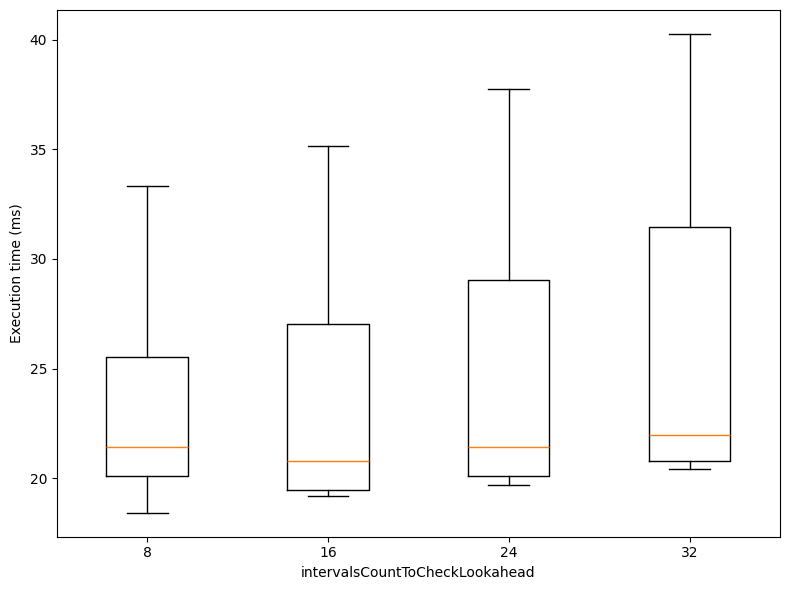

In [52]:
plot_configuration_boxplot("intervalsCountToCheckLookahead")

### intervalsCountToTriggerExtractionFraction
This parameter controls number of intervals necessary to eject an interval from the component. Its value corresponds to `1/n` of intervalsCountToCheckLookahead value - e.g. value of 4 means if 1/4 or more of checked intervals are shadowed, the interval is ejected. 
This parameter will not be tested further and value of 2 (meaning 1/2 of intervalsCountToCheckLookahead) will be used.

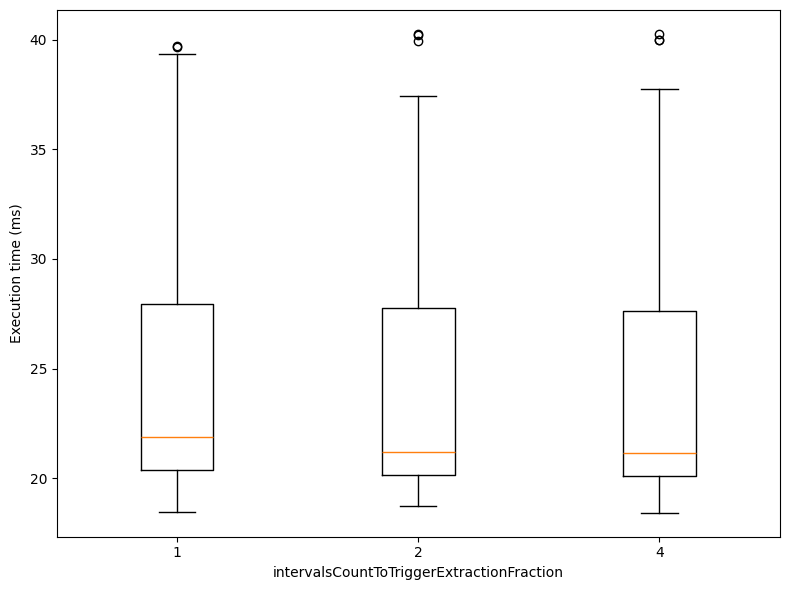

In [53]:
plot_configuration_boxplot("intervalsCountToTriggerExtractionFraction")

### maximumComponentSize
This parameter controls the maximum number of intervals in each component. In practice it is also bounded by Apache Spark partition size recommendations and higher values are not considered. 
This parameter will not be tested further and value of 100.000 will be used.

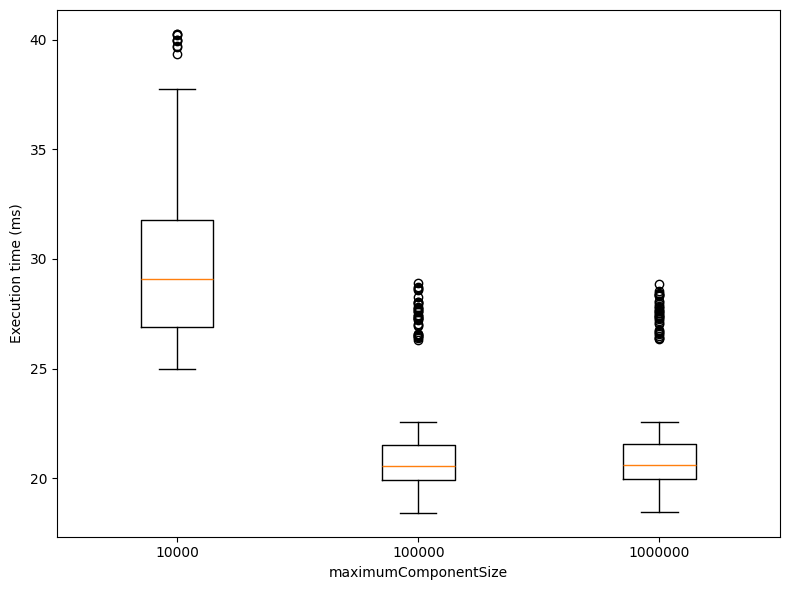

In [54]:
plot_configuration_boxplot("maximumComponentSize")

### earlyStopLeftoverCount
This parameter controls number of intervals necessary to continue the algorithm. If there are less than specified intervals left, all are sent to the last component and AIList building is finished. 
This parameter will not be tested further and value of 100 will be used.

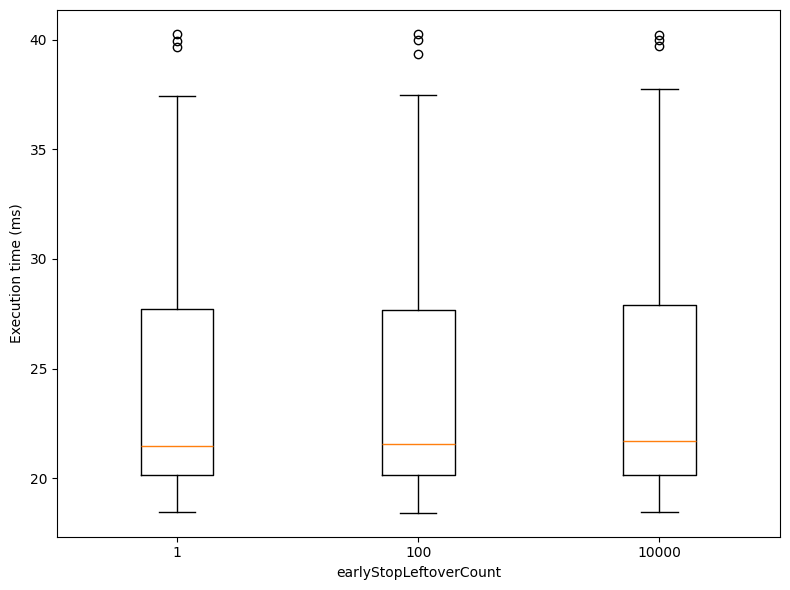

In [55]:
plot_configuration_boxplot("earlyStopLeftoverCount")